# ReviewIQ AI – Deliverable 2 (Phase 3 & 4)
Upload the 3 clean CSVs from Deliverable 1 to Colab first.

In [1]:
# STEP 1: Load data and libraries
# Purpose: bring in the cleaned train/validation/test files from Deliverable 1
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
    roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay, classification_report)
from sklearn.model_selection import learning_curve
from sklearn.preprocessing import label_binarize

train = pd.read_csv("reviews_train_clean.csv")
val   = pd.read_csv("reviews_validation_clean.csv")
test  = pd.read_csv("reviews_test_clean.csv")
classes = ["Negative", "Neutral", "Positive"]
print(train.shape, val.shape, test.shape)

(29960, 7) (2992, 7) (2990, 7)


In [2]:
# STEP 2: TF-IDF features
# Purpose: turn text into numbers. Fit on TRAIN only to avoid data leakage.
vec = TfidfVectorizer(max_features=10000, ngram_range=(1, 2))
Xtr = vec.fit_transform(train["cleaned_review"])
Xva = vec.transform(val["cleaned_review"])
Xte = vec.transform(test["cleaned_review"])
ytr, yva, yte = train["sentiment"], val["sentiment"], test["sentiment"]
print(Xtr.shape, Xva.shape, Xte.shape)

(29960, 10000) (2992, 10000) (2990, 10000)


In [3]:
# STEP 3: Hyperparameter tuning (Phase 3 table)
# Purpose: try 3 models x 3 settings, compare on the VALIDATION set only
rows = []
def run(name, param, model):
    model.fit(Xtr, ytr)
    p = model.predict(Xva)
    rows.append((name, param, accuracy_score(yva, p), f1_score(yva, p, average="macro")))

for C in [0.1, 1, 10]:
    run("Logistic Regression", f"C={C}", LogisticRegression(C=C, max_iter=1000, class_weight="balanced"))
for C in [0.01, 0.1, 1]:
    run("Linear SVM", f"C={C}", LinearSVC(C=C, class_weight="balanced"))
for a in [0.1, 0.5, 1.0]:
    run("Naive Bayes", f"alpha={a}", MultinomialNB(alpha=a))

results = pd.DataFrame(rows, columns=["Model", "Parameter", "Val Accuracy", "Val Macro-F1"]).round(4)
results

,Model,Parameter,Val Accuracy,Val Macro-F1
0,Logistic Regression,C=0.1,0.6801,0.6521
1,Logistic Regression,C=1,0.6905,0.6562
2,Logistic Regression,C=10,0.6654,0.6267
3,Linear SVM,C=0.01,0.6982,0.6271
4,Linear SVM,C=0.1,0.7136,0.6566
5,Linear SVM,C=1,0.6905,0.6392
6,Naive Bayes,alpha=0.1,0.7106,0.6205
7,Naive Bayes,alpha=0.5,0.7059,0.6031
8,Naive Bayes,alpha=1.0,0.7059,0.5882


In [4]:
# STEP 4: Pick the best model and train it
# Purpose: choose by highest validation macro-F1 (fair for the smaller Neutral class)
best = results.loc[results["Val Macro-F1"].idxmax()]
print("Best:", best["Model"], best["Parameter"])

model = LinearSVC(C=0.1, class_weight="balanced")   # change if your best row differs
model.fit(Xtr, ytr)

Best: Linear SVM C=0.1


LinearSVC(C=0.1, class_weight='balanced')

In [5]:
# STEP 5: Test-set evaluation (Phase 4 metrics)
# Purpose: final, unbiased performance on data the model never saw
pred = model.predict(Xte)
print("Accuracy:", round(accuracy_score(yte, pred), 4))
print(classification_report(yte, pred, digits=4))

# AUC-ROC (one-vs-rest, needs scores per class)
scores = model.decision_function(Xte)
y_bin = label_binarize(yte, classes=model.classes_)
auc_macro = roc_auc_score(y_bin, scores, average="macro")
print("Macro AUC-ROC:", round(auc_macro, 4))
for i, c in enumerate(model.classes_):
    print(c, "AUC:", round(roc_auc_score(y_bin[:, i], scores[:, i]), 4))

Accuracy: 0.7047
              precision    recall  f1-score   support

    Negative     0.7365    0.7870    0.7609      1197
     Neutral     0.4228    0.3339    0.3731       599
    Positive     0.7795    0.8082    0.7936      1194

    accuracy                         0.7047      2990
   macro avg     0.6463    0.6430    0.6425      2990
weighted avg     0.6908    0.7047    0.6963      2990

Macro AUC-ROC: 0.8375
Negative AUC: 0.8839
Neutral AUC: 0.7106
Positive AUC: 0.9178


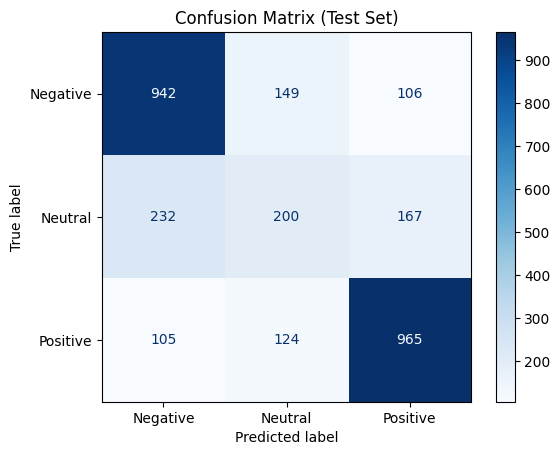

In [6]:
# STEP 6: Confusion matrix
# Purpose: see exactly which classes get confused
cm = confusion_matrix(yte, pred, labels=classes)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix (Test Set)")
plt.savefig("confusion_matrix.png", dpi=200, bbox_inches="tight"); plt.show()

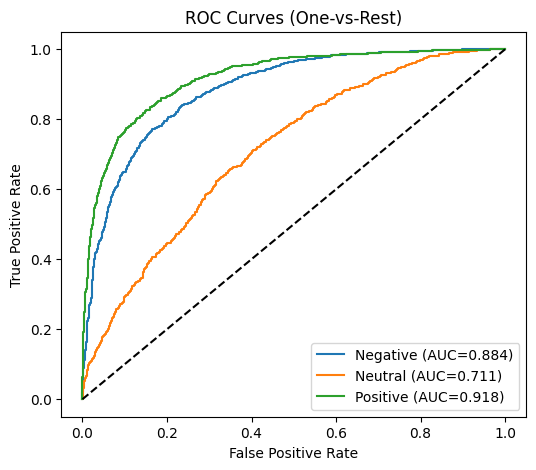

In [7]:
# STEP 7: ROC curves
# Purpose: show class-wise AUC-ROC visually
plt.figure(figsize=(6, 5))
for i, c in enumerate(model.classes_):
    fpr, tpr, _ = roc_curve(y_bin[:, i], scores[:, i])
    plt.plot(fpr, tpr, label=f"{c} (AUC={roc_auc_score(y_bin[:, i], scores[:, i]):.3f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves (One-vs-Rest)"); plt.legend()
plt.savefig("roc_curves.png", dpi=200, bbox_inches="tight"); plt.show()

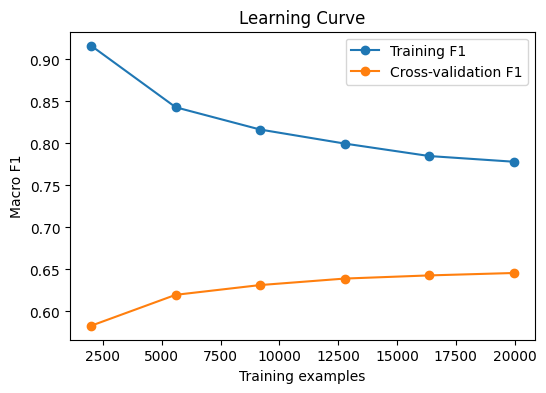

In [8]:
# STEP 8: Learning curve (the "accuracy curve" for the report)
# Purpose: show how performance changes with more training data
sizes, tr_sc, va_sc = learning_curve(LinearSVC(C=0.1, class_weight="balanced"), Xtr, ytr,
    train_sizes=np.linspace(0.1, 1.0, 6), cv=3, scoring="f1_macro", random_state=42)
plt.figure(figsize=(6, 4))
plt.plot(sizes, tr_sc.mean(axis=1), "o-", label="Training F1")
plt.plot(sizes, va_sc.mean(axis=1), "o-", label="Cross-validation F1")
plt.xlabel("Training examples"); plt.ylabel("Macro F1"); plt.title("Learning Curve"); plt.legend()
plt.savefig("learning_curve.png", dpi=200, bbox_inches="tight"); plt.show()

In [9]:
# STEP 9: Error analysis
# Purpose: find where the model fails
test["pred"] = pred
errors = test[test["sentiment"] != test["pred"]]
print("Total errors:", len(errors), "of", len(test))
print(pd.crosstab(errors["sentiment"], errors["pred"]))
print("\nSample errors:")
for _, r in errors.sample(6, random_state=1).iterrows():
    print(f"TRUE={r.sentiment} | PRED={r.pred} | {r.review[:150]}\n")

Total errors: 883 of 2990
pred       Negative  Neutral  Positive
sentiment                             
Negative          0      149       106
Neutral         232        0       167
Positive        105      124         0

Sample errors:
TRUE=Neutral | PRED=Negative | Runs very large. Order 3 sizes smaller!

TRUE=Positive | PRED=Neutral | I wanted to give one star. Not for the quality of the book or the writing but for the story. Crushing. I'd like to read an update from the author.

TRUE=Neutral | PRED=Negative | The brushes are already starting to fray after only a few uses, I’ve even had to trim some stragglers from the sides with scissors!! But in the beginn

TRUE=Positive | PRED=Neutral | this remote control is definitely not the same quality as my original controller ! It seems to work OK sometimes the buttons are less responsive I had

TRUE=Neutral | PRED=Negative | It’s a nice looking item that keeps my puppy safe but after a few weeks some of the holes where the zip ties go thr

In [10]:
# STEP 10: Bias check
# Purpose: check if the model is unfair to certain classes or review lengths
test["length_group"] = pd.cut(test["word_count"], bins=[0, 15, 40, 1000], labels=["Short (<=15)", "Medium (16-40)", "Long (>40)"])
test["correct"] = (test["sentiment"] == test["pred"])
print("Accuracy by length group:"); print(test.groupby("length_group", observed=True)["correct"].agg(["mean", "count"]).round(4))
print("\nAccuracy by original rating (1-5 stars = 0-4):"); print(test.groupby("label")["correct"].mean().round(4))
print("\nPer-class recall:")
p, r, f, s = precision_recall_fscore_support(yte, pred, labels=classes)
print(pd.DataFrame({"precision": p, "recall": r, "f1": f, "support": s}, index=classes).round(4))

Accuracy by length group:
                  mean  count
length_group                 
Short (<=15)    0.7287    962
Medium (16-40)  0.7124   1165
Long (>40)      0.6674    863

Accuracy by original rating (1-5 stars = 0-4):
label
0    0.8894
1    0.6850
2    0.3339
3    0.7157
4    0.9010
Name: correct, dtype: float64

Per-class recall:
          precision  recall      f1  support
Negative     0.7365  0.7870  0.7609     1197
Neutral      0.4228  0.3339  0.3731      599
Positive     0.7795  0.8082  0.7936     1194


In [11]:
# STEP 11: Save the model (for the repo)
import joblib
joblib.dump(model, "svm_model.joblib"); joblib.dump(vec, "tfidf_vectorizer.joblib")

['tfidf_vectorizer.joblib']